<a href="https://colab.research.google.com/github/IvonneRomero1008/IA-Trabajos-escolares/blob/main/Practica5__CNN_clasificacion_de_digitos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

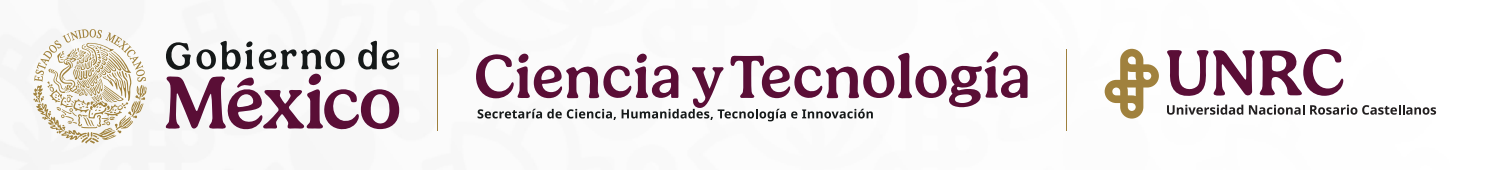

Practica5_ CNN_clasificacion_de_digitos.ipynb


 * **Actualizado**:04 de Noviembre 2026  

 * **Autor**: Ivonne America Romero Lara

 * **Github**:IvonneRomero1008

# Introducción

En esta práctica se desarrollará una red neuronal convolucional (CNN) para clasificar imágenes de dígitos escritos a mano, identificando números del 0 al 9.

Para realizar el ejercicio se utilizará un conjunto de datos que contiene imágenes pequeñas en escala de grises. La red neuronal analizará estas imágenes, aprenderá a reconocer sus características y posteriormente realizará predicciones para identificar qué número aparece en cada una.

Durante el desarrollo se realizarán diferentes etapas: carga y exploración de los datos, preparación de las imágenes, construcción de la red neuronal, entrenamiento y evaluación del modelo.

El propósito de esta actividad es comprender cómo funciona una CNN y cómo puede utilizarse para resolver problemas de clasificación de imágenes

# Desarrollo



# 1. Importación y carga de datos

Para desarrollar la práctica utilizaremos diferentes bibliotecas de Python.(colab)

NumPy permitirá trabajar con matrices y valores numéricos; Matplotlib y Seaborn permitirán visualizar imágenes y gráficas; Scikit-learn facilitará la preparación y evaluación de los datos; y TensorFlow con Keras permitirá construir y entrenar la red neuronal.

Posteriormente cargaremos el conjunto de datos de dígitos escritos a mano.

In [1]:
# Importamos bibliotecas para trabajar con datos numéricos
import numpy as np

# Importamos herramientas para visualizar imágenes y gráficas
import matplotlib.pyplot as plt
import seaborn as sns

# Importamos TensorFlow para construir la red neuronal
import tensorflow as tf

# Carga de conjunto de datos de dígitos
from sklearn.datasets import load_digits

# Herramientas para preparar y dividir los datos
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Herramientas para evaluar el modelo
from sklearn.metrics import confusion_matrix, recall_score
from sklearn.metrics import classification_report

# Importar las capas de la red neuronal
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Flatten
from tensorflow.keras.layers import Conv2D, MaxPooling2D

# Importar el optimizador
from tensorflow.keras.optimizers import Adam

# Establecer semillas para facilitar la reproducción
np.random.seed(42)
tf.random.set_seed(42)

# Cargar los datos
digitos = load_digits()

# Guardar las imágenes y sus etiquetas
imagenes = digitos.images
etiquetas = digitos.target

# Mostrar información general
print("Cantidad de imágenes:", len(imagenes))
print("Dimensiones de las imágenes:", imagenes.shape)
print("Clases disponibles:", np.unique(etiquetas))

Cantidad de imágenes: 1797
Dimensiones de las imágenes: (1797, 8, 8)
Clases disponibles: [0 1 2 3 4 5 6 7 8 9]


Matriz de la imagen:
[[ 0.  0.  5. 13.  9.  1.  0.  0.]
 [ 0.  0. 13. 15. 10. 15.  5.  0.]
 [ 0.  3. 15.  2.  0. 11.  8.  0.]
 [ 0.  4. 12.  0.  0.  8.  8.  0.]
 [ 0.  5.  8.  0.  0.  9.  8.  0.]
 [ 0.  4. 11.  0.  1. 12.  7.  0.]
 [ 0.  2. 14.  5. 10. 12.  0.  0.]
 [ 0.  0.  6. 13. 10.  0.  0.  0.]]
Número real: 0


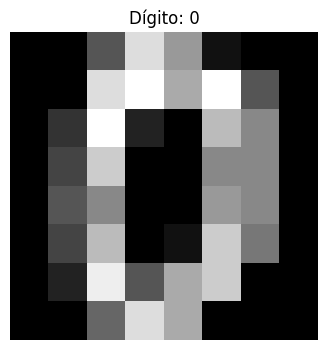

In [2]:
# Seleccionamos una imagen del conjunto de datos
indice = 0

# Obtener la imagen y su etiqueta
imagen = imagenes[indice]
numero_real = etiquetas[indice]

# Mostrar los valores numéricos de la imagen
print("Matriz de la imagen:")
print(imagen)

print("Número real:", numero_real)

# Mostrar la imagen visualmente
plt.figure(figsize=(4, 4))
plt.imshow(imagen, cmap="gray")
plt.title("Dígito: " + str(numero_real))
plt.axis("off")
plt.show()

In [3]:
# Convertir cada imagen de 8x8 en una fila de 64 valores
datos = imagenes.reshape(len(imagenes), 64)

# Separar los datos para entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    datos,
    etiquetas,
    test_size=0.20,
    random_state=42,
    stratify=etiquetas
)

# Normalizar los datos
escalador = StandardScaler()
X_train = escalador.fit_transform(X_train)
X_test = escalador.transform(X_test)

# Acomodar las imágenes para la red neuronal convolucional
X_train = X_train.reshape(-1, 8, 8, 1)
X_test = X_test.reshape(-1, 8, 8, 1)

# Mostrar las dimensiones obtenidas
print("Datos de entrenamiento:", X_train.shape)
print("Datos de prueba:", X_test.shape)
print("Etiquetas de entrenamiento:", y_train.shape)
print("Etiquetas de prueba:", y_test.shape)

Datos de entrenamiento: (1437, 8, 8, 1)
Datos de prueba: (360, 8, 8, 1)
Etiquetas de entrenamiento: (1437,)
Etiquetas de prueba: (360,)


In [4]:
# Crear la estructura de la red neuronal convolucional
modelo = Sequential([
    # Recibir imágenes de 8x8 píxeles y un canal
    Input(shape=(8, 8, 1)),

    # Detectar características de las imágenes
    Conv2D(32, kernel_size=(3, 3), activation="relu"),

    # Reducir las dimensiones conservando características importantes
    MaxPooling2D(pool_size=(2, 2)),

    # Convertir los resultados en un vector
    Flatten(),

    # Capa oculta para aprender patrones
    Dense(128, activation="relu"),

    # Clasificar entre los 10 dígitos posibles
    Dense(10, activation="softmax")
])

# Mostrar el resumen de la arquitectura
modelo.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 6, 6, 32)       │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 3, 3, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 288)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        36,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 38,602 (150.79 KB)

 Trainable params: 38,602 (150.79 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
# Configurar el proceso de aprendizaje
modelo.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Entrenar la red neuronal
historial = modelo.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=32,
    validation_split=0.20
)

Epoch 1/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - accuracy: 0.6406 - loss: 1.5926 - val_accuracy: 0.8438 - val_loss: 0.9370
Epoch 2/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.9243 - loss: 0.5150 - val_accuracy: 0.9201 - val_loss: 0.3767
Epoch 3/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9582 - loss: 0.2235 - val_accuracy: 0.9375 - val_loss: 0.2467
Epoch 4/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9713 - loss: 0.1405 - val_accuracy: 0.9479 - val_loss: 0.1861
Epoch 5/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9852 - loss: 0.0996 - val_accuracy: 0.9618 - val_loss: 0.1494
Epoch 6/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9878 - loss: 0.0748 - val_accuracy: 0.9653 - val_loss: 0.1258
Epoch 7/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9904 - loss: 0.0579 - val_accuracy: 0.9653 - val_loss: 0.1100
Epoch 8/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9956 - loss: 0.0454 - val_accuracy: 0.9688 - va

In [7]:
#Evaluar el modelo con imágenes que no utilizó para entrenarse
perdida, exactitud = modelo.evaluate(X_test, y_test)

print("Pérdida del modelo:", perdida)
print("Exactitud del modelo:", exactitud)

# Obtener las predicciones
probabilidades = modelo.predict(X_test)
predicciones = np.argmax(probabilidades, axis=1)

# Comparar los primeros 10 resultados
print("Dígitos reales:     ", y_test[:10])
print("Dígitos predichos:  ", predicciones[:10])

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9778 - loss: 0.1037  
Pérdida del modelo: 0.1036875918507576
Exactitud del modelo: 0.9777777791023254
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
Dígitos reales:      [5 2 8 1 7 2 6 2 6 5]
Dígitos predichos:   [5 2 8 1 7 2 6 2 6 5]


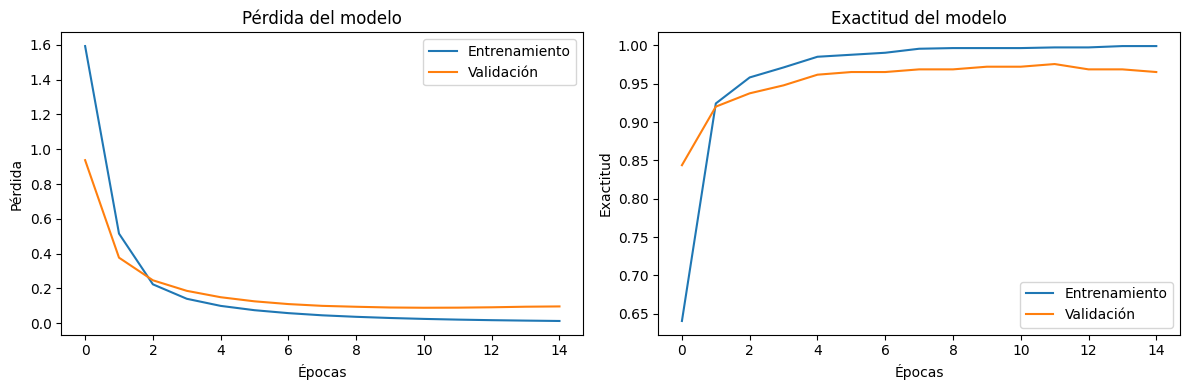

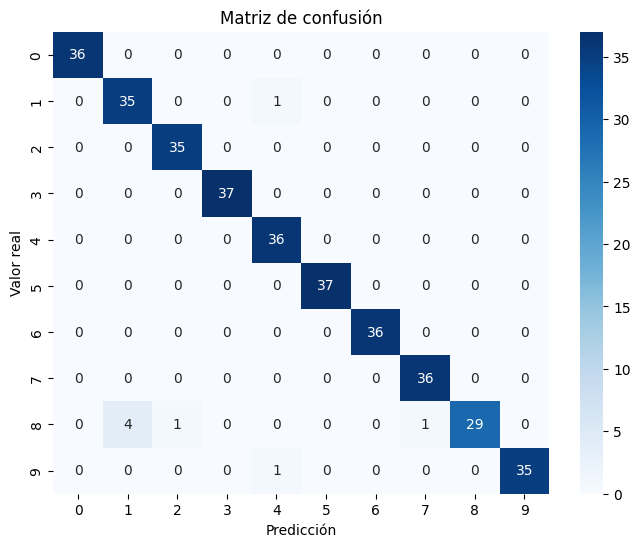

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       0.90      0.97      0.93        36
           2       0.97      1.00      0.99        35
           3       1.00      1.00      1.00        37
           4       0.95      1.00      0.97        36
           5       1.00      1.00      1.00        37
           6       1.00      1.00      1.00        36
           7       0.97      1.00      0.99        36
           8       1.00      0.83      0.91        35
           9       1.00      0.97      0.99        36

    accuracy                           0.98       360
   macro avg       0.98      0.98      0.98       360
weighted avg       0.98      0.98      0.98       360



In [8]:
# Graficar la pérdida y la exactitud durante el entrenamiento
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(historial.history["loss"], label="Entrenamiento")
plt.plot(historial.history["val_loss"], label="Validación")
plt.title("Pérdida del modelo")
plt.xlabel("Épocas")
plt.ylabel("Pérdida")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(historial.history["accuracy"], label="Entrenamiento")
plt.plot(historial.history["val_accuracy"], label="Validación")
plt.title("Exactitud del modelo")
plt.xlabel("Épocas")
plt.ylabel("Exactitud")
plt.legend()

plt.tight_layout()
plt.show()

# Crear la matriz de confusión
matriz = confusion_matrix(y_test, predicciones)

plt.figure(figsize=(8, 6))
sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues")
plt.title("Matriz de confusión")
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.show()

# Mostrar las métricas de clasificación
print(classification_report(y_test, predicciones))

## Conclusiones

En esta práctica se construyó y entrenó una red neuronal convolucional (CNN) para clasificar imágenes de dígitos escritos a mano del 0 al 9.

Se utilizó el conjunto de datos load_digits() de Scikit-learn, compuesto por 1,797 imágenes de 8 × 8 píxeles. Los datos se dividieron en un conjunto de entrenamiento y otro de prueba.

Durante el desarrollo se utilizaron capas convolucionales, de agrupamiento y capas densas para que el modelo aprendiera a identificar las características de cada dígito.

La exactitud obtenida durante la evaluación fue de: *escribir aquí el resultado*.

A partir de los resultados, se puede concluir que la red neuronal convolucional *explica brevemente qué tan bien clasificó los dígitos y si presentó confusiones*.

Esta práctica permitió comprender las etapas de preparación de datos, construcción, entrenamiento y evaluación de una red neuronal convolucional

# Referencias

Scikit-learn developers. (s. f.). load_digits. Scikit-learn.
https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html

TensorFlow. (s. f.). tf.keras.layers.Conv2D.
https://www.tensorflow.org/api_docs/python/tf/keras/layers/Conv2D

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. Journal of Machine Learning Research, 12, 2825–2830.
https://jmlr.org/papers/v12/pedregosa11a.html